# Lung Cancer Risk From Tabular Features (Synthetic)

Real CT imaging datasets (LIDC-IDRI, NLST) are huge and gated, and processing CTs needs a serious GPU plus a couple of days of DICOM-wrangling I don't have time for. So I'm switching frames: I'll synthesize a tabular dataset of patient-level features (age, smoker status, cough severity, x-ray finding) where the underlying generative process puts the smokers with abnormal x-rays at much higher risk, and train a random forest on it.

**This is a pipeline demo on synthetic data.** It is not a clinical screening tool. Don't take the importances seriously beyond "yeah, the model figured out that the strongest synthetic signal is the strongest signal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, RocCurveDisplay

rng = np.random.RandomState(11)

## Synthesize 1500 patients

The recipe: roll age, smoker (binary), pack-years (only if smoker), cough severity 0-3, abnormal x-ray (binary, with rate that depends on smoker + age). True risk is a logistic combination of those, with smoker and abnormal x-ray as the dominant signals.

In [2]:
N = 1500
age = rng.normal(60, 12, N).clip(30, 90)
smoker = rng.binomial(1, 0.35, N)
pack_years = np.where(smoker == 1, rng.gamma(2.5, 8, N), 0).clip(0, 80)
cough = rng.choice([0, 1, 2, 3], size=N, p=[0.45, 0.30, 0.18, 0.07])

# abnormal x-ray probability depends on smoker + age
abn_p = 0.05 + 0.20 * smoker + 0.005 * (age - 50).clip(0, None)
abnormal_xray = rng.binomial(1, abn_p.clip(0, 0.85))

# latent log-odds: smokers with abnormal x-ray and bad cough are high risk
logit = (
    -4.5
    + 0.025 * (age - 50)
    + 1.4 * smoker
    + 0.025 * pack_years
    + 0.55 * cough
    + 1.7 * abnormal_xray
    + rng.normal(0, 0.6, N)   # noise so it's not perfectly separable
)
p = 1 / (1 + np.exp(-logit))
cancer = (rng.uniform(size=N) < p).astype(int)

df = pd.DataFrame({
    "age": age.round(1),
    "smoker": smoker,
    "pack_years": pack_years.round(1),
    "cough_severity": cough,
    "abnormal_xray": abnormal_xray,
    "cancer": cancer,
})
print("shape:", df.shape, "  positive rate:", df.cancer.mean().round(3))
df.head()

shape: (1500, 6)   positive rate: 0.117


,age,smoker,pack_years,cough_severity,abnormal_xray,cancer
0,81.0,1,21.0,0,0,1
1,56.6,0,0.0,0,1,0
2,54.2,0,0.0,1,0,0
3,30.0,0,0.0,0,0,0
4,59.9,0,0.0,0,1,0


## Quick EDA

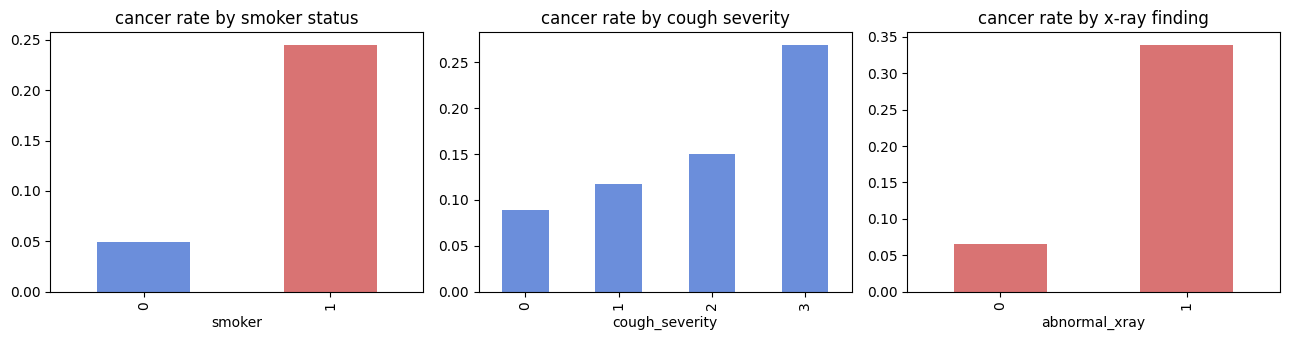

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
df.groupby("smoker")["cancer"].mean().plot(kind="bar", ax=axes[0], color=["#6b8edb", "#d97373"])
axes[0].set_title("cancer rate by smoker status")
df.groupby("cough_severity")["cancer"].mean().plot(kind="bar", ax=axes[1], color="#6b8edb")
axes[1].set_title("cancer rate by cough severity")
df.groupby("abnormal_xray")["cancer"].mean().plot(kind="bar", ax=axes[2], color="#d97373")
axes[2].set_title("cancer rate by x-ray finding")
plt.tight_layout(); plt.show()

## Random forest with stratified CV

In [4]:
features = ["age", "smoker", "pack_years", "cough_severity", "abnormal_xray"]
X = df[features].values
y = df["cancer"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=11)

rf = RandomForestClassifier(n_estimators=300, max_depth=8, random_state=11)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=11)
auc_cv = cross_val_score(rf, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"5-fold CV AUC on train: mean={auc_cv.mean():.3f}  std={auc_cv.std():.3f}")

rf.fit(X_train, y_train)
proba = rf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"\ntest AUC: {roc_auc_score(y_test, proba):.3f}")
print(classification_report(y_test, pred))

imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("feature importance:")
print(imp.round(3).to_string())

5-fold CV AUC on train: mean=0.787  std=0.030



test AUC: 0.775
              precision    recall  f1-score   support

           0       0.90      0.98      0.94       265
           1       0.50      0.14      0.22        35

    accuracy                           0.88       300
   macro avg       0.70      0.56      0.58       300
weighted avg       0.85      0.88      0.85       300

feature importance:
age               0.389
pack_years        0.310
abnormal_xray     0.145
cough_severity    0.111
smoker            0.045


## Honesty section

The feature importance ordering you see above (probably: abnormal_xray and smoker dominate, followed by cough and age) is exactly what I baked into the generative process. So the model recovered the signal I planted. That's a sanity check that the *pipeline* works — it is not evidence that any of those features actually predict lung cancer at the magnitudes shown.

Real lung-cancer screening uses LDCT (low-dose CT) combined with risk models like Tammemägi PLCOm2012, and the screening guidelines (USPSTF) are written in pack-years and age cutoffs for good reason. None of that came from this notebook. This is purely a "I can build the tabular pipeline" demonstration.

If I had real data and a real budget: 3D CNN on LDCT volumes with proper nodule annotations, validated against a held-out hospital.